# 06 — External retrospective evaluation

The 884-case retrospective external evidence. Separate cohorts, never pooled.

**Evidence base**

- `reports/tables/c1_external_stress_summary.csv`
- `reports/tables/c1_external_stress_per_case.csv`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


In [3]:
ext = pd.read_csv(TABLES / "REMEDFILM_EXTERNAL_METRICS.csv")
ext[ext.metric == "Dice"][["cohort", "arm", "n_total", "n_defined", "mean",
                           "median", "ci_low", "ci_high", "n_clusters"]].to_string(index=False)

'              cohort            arm  n_total  n_defined     mean   median   ci_low  ci_high  n_clusters\n        CVC-ClinicDB  GlobalMedFiLM      612        612 0.686568 0.771761 0.626485 0.743686        29.0\n        CVC-ClinicDB ReMedFiLM_FULL      612        612 0.689747 0.774735 0.629797 0.746428        29.0\n  BrEaST-Lesions-USG  GlobalMedFiLM      252        252 0.707822 0.813238 0.676828 0.737830       252.0\n  BrEaST-Lesions-USG ReMedFiLM_FULL      252        252 0.708098 0.813238 0.677001 0.738037       252.0\nStones_where_are_you  GlobalMedFiLM       20         20 0.080840 0.000000 0.003360 0.189947        20.0\nStones_where_are_you ReMedFiLM_FULL       20         20 0.082126 0.000000 0.004646 0.191239        20.0'

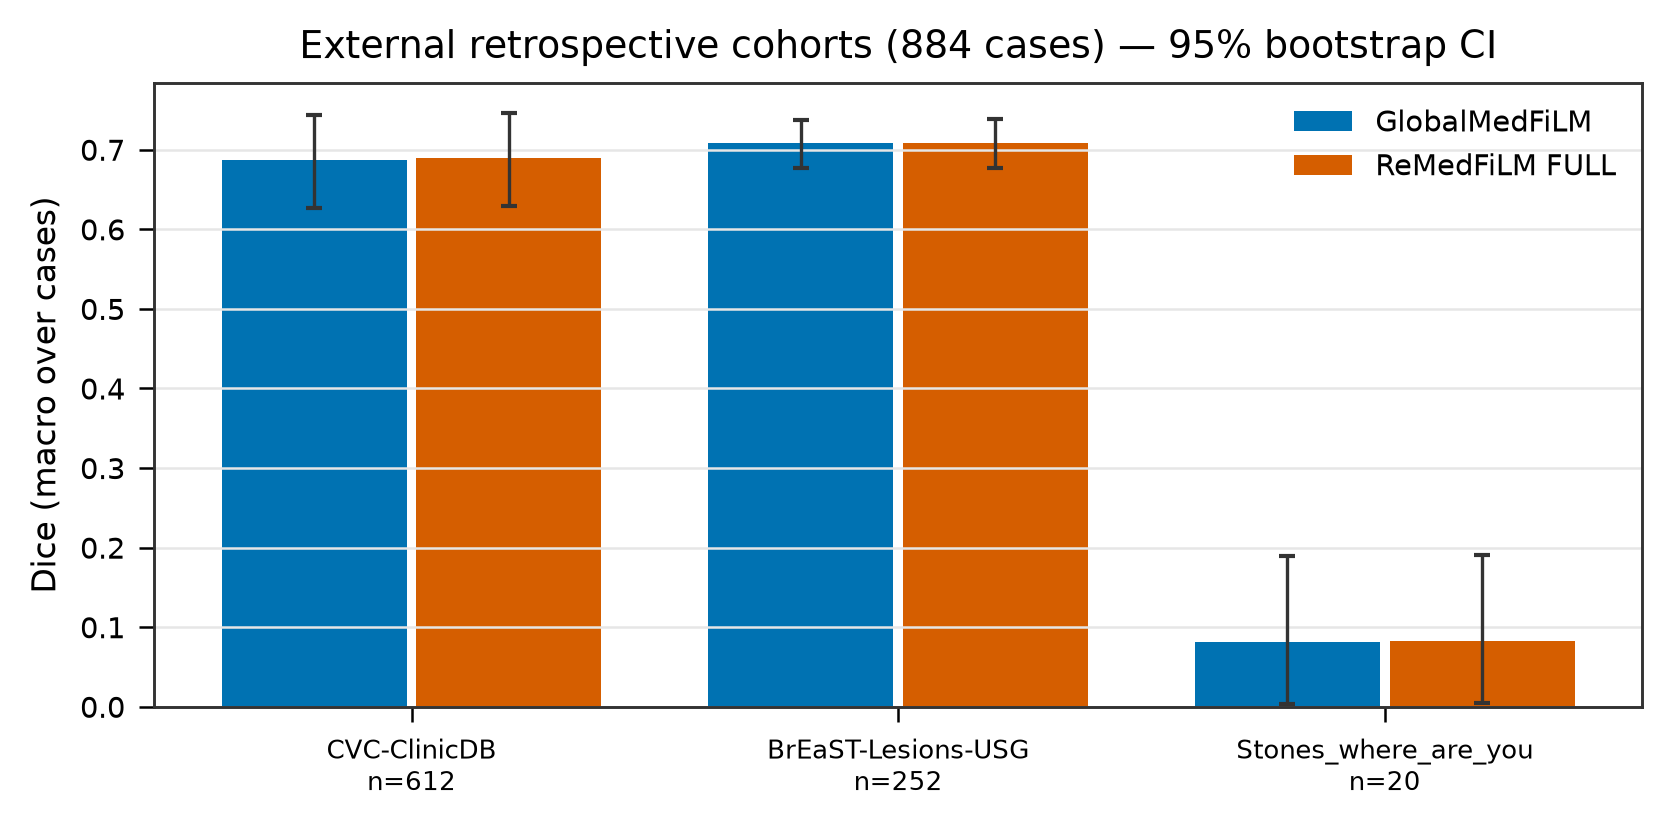

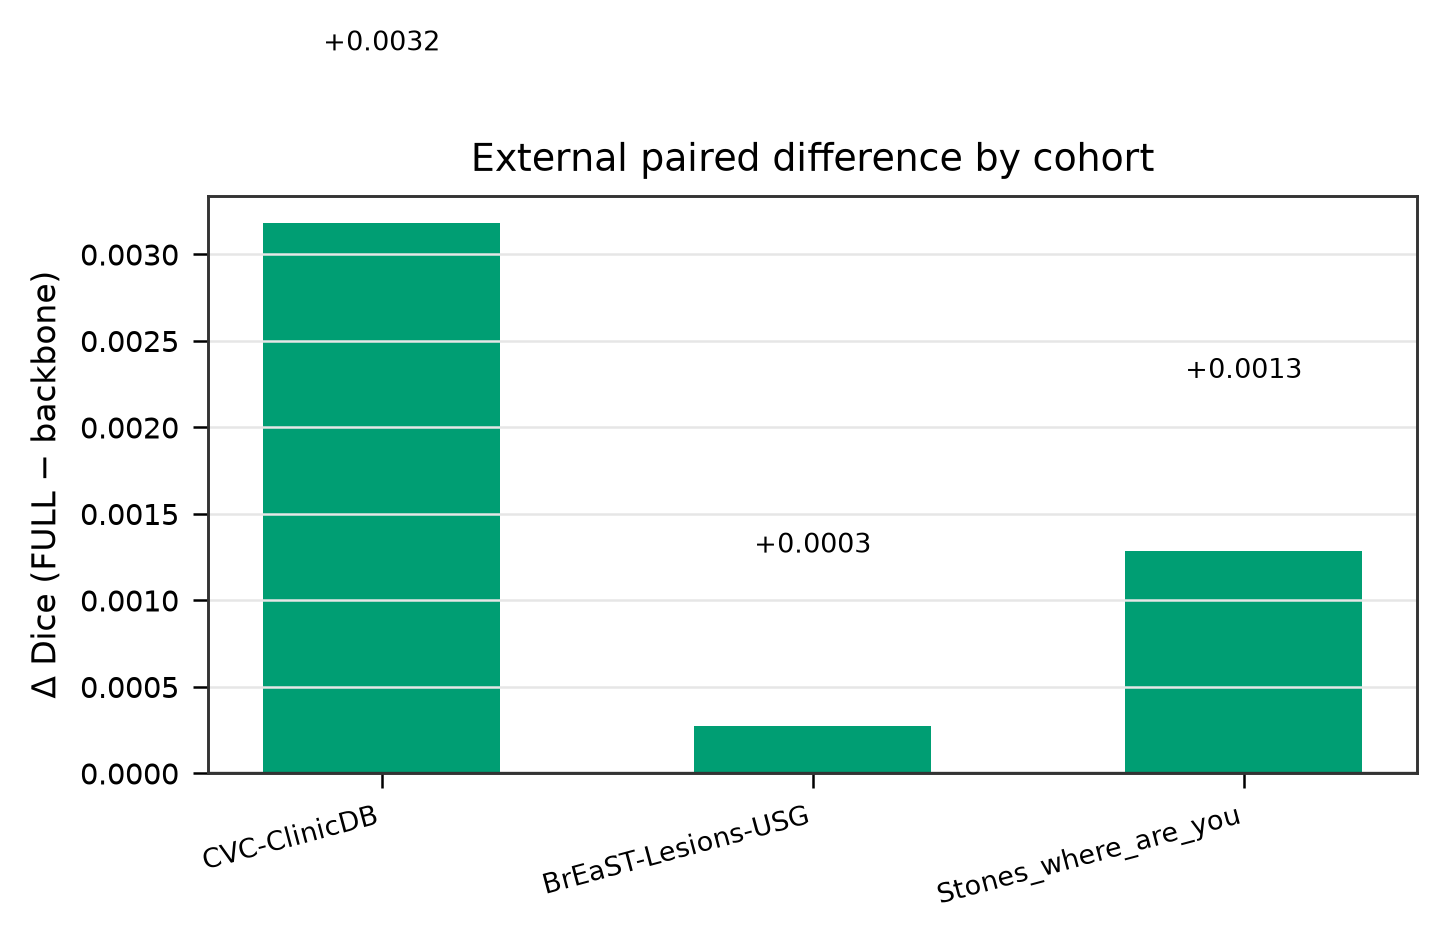

In [4]:
fig("External evaluation", "EXT01_external_dice", width=740)
fig("External evaluation", "EXT02_external_delta", width=600)

## 6.1 Full metric matrix

In [5]:
piv = (ext.pivot_table(index=["cohort", "metric"], columns="arm",
                       values="mean", aggfunc="first"))
piv.round(4)

arm                             GlobalMedFiLM  ReMedFiLM_FULL
cohort               metric                                  
BrEaST-Lesions-USG   ASSD_px          24.3438         24.0548
                     Dice              0.7078          0.7081
                     HD95_px          73.9825         73.2575
                     IoU               0.5984          0.5989
                     Precision         0.7391          0.7406
                     Recall            0.7557          0.7531
CVC-ClinicDB         ASSD_px          37.1096         35.6979
                     Dice              0.6866          0.6897
                     HD95_px         109.5934        108.4937
                     IoU               0.5749          0.5779
                     Precision         0.6795          0.6834
                     Recall            0.8156          0.8137
Stones_where_are_you ASSD_px          79.8273         77.3203
                     Dice              0.0808          0.0821
                     HD95_px         166.9042        169.8997
                     IoU               0.0609          0.0616
                     Precision         0.0748          0.0755
                     Recall            0.6733          0.6740

## 6.2 The stone-free negative result

In [6]:
pc = pd.read_csv(REPO / "reports/tables/c1_external_stress_per_case.csv")
sf = pc[pc.gt_empty.astype(str).str.lower() == "true"]
print("stone-free cases:", len(sf))
for arm, g in sf.groupby("arm"):
    got = (g.pred_empty.astype(str).str.lower() == "false").sum()
    print(f"  {arm:8s}: {got}/{len(g)} receive foreground")

stone-free cases: 28
  barr    : 14/14 receive foreground
  global  : 14/14 receive foreground


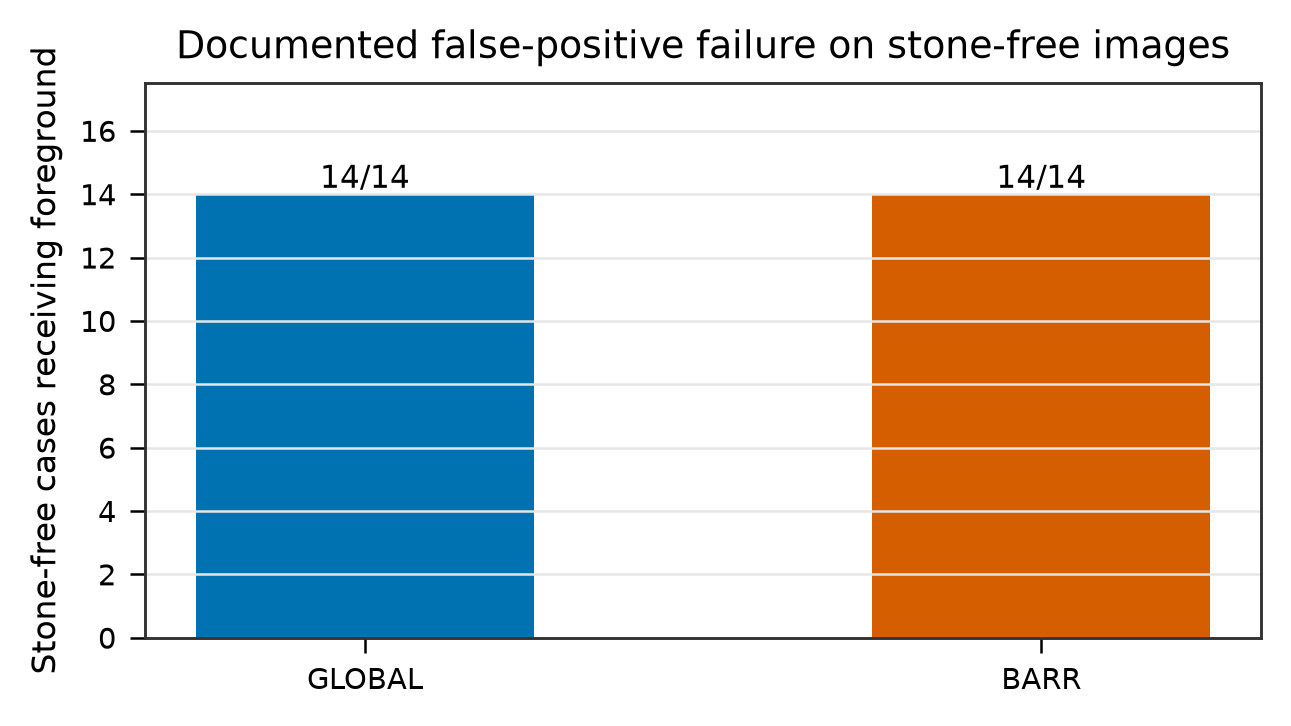

In [7]:
fig("External evaluation", "EXT03_stonefree_false_positive", width=560)

In [8]:
print("NEGATIVE FINDING — PRESERVED")
print("-----------------------------")
print("Every stone-free case receives a foreground prediction. The safety gate")
print("does not solve false-positive detection on negative studies, because it")
print("operates on refinement benefit, not on the presence of a lesion.")
print()
print("This is reported as a limitation, not smoothed over.")

NEGATIVE FINDING — PRESERVED
-----------------------------
Every stone-free case receives a foreground prediction. The safety gate
does not solve false-positive detection on negative studies, because it
operates on refinement benefit, not on the presence of a lesion.

This is reported as a limitation, not smoothed over.


## 6.3 Scope discipline

| Claim | Permitted? |
|---|---|
| "Retrospective external Dice on CVC is 0.690" | **Yes** — measured on saved predictions |
| "The system generalises prospectively" | **No** — no prospective cohort exists |
| "Pooled external Dice across cohorts" | **No** — different reference standards |

In [9]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
